# Modelo predictivo de riesgo crediticio

**Universidad Nacional Autónoma de Honduras · IS-701 Inteligencia Artificial · III PAC 2026**

Objetivo: entrenar un modelo que clasifique a un solicitante en tres niveles de riesgo a partir de 10 variables del dataset *Credit Score Classification* (`train.csv`).

| Clase | `Credit_Score` original | Nivel de riesgo |
|---|---|---|
| 0 | Good | Riesgo bajo |
| 1 | Standard | Riesgo medio |
| 2 | Poor | Riesgo alto |

Proceso: carga → exploración → corrección de formatos → imputación de nulos → eliminación de atípicos (IQR) → codificación → división entrenamiento/prueba → escalado estándar → entrenamiento (KNN, Árbol de decisión, SVC) → evaluación → guardado.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from modelo.configuracion import (RUTA_DATOS, COLUMNAS_MODELO, COLUMNAS_NUMERICAS, COLUMNAS_CATEGORICAS,
                                  COLUMNA_OBJETIVO, ETIQUETAS_RIESGO)
from modelo import preprocesamiento as pp
from modelo import entrenamiento as ent

pd.set_option('display.float_format', '{:.2f}'.format)

## 1. Carga y exploración de los datos

In [2]:
df_original = pd.read_csv(RUTA_DATOS, low_memory=False)
print('Dimensiones del dataset completo:', df_original.shape)

df = pp.cargar_datos(RUTA_DATOS)
print('Dimensiones con las columnas seleccionadas:', df.shape)
df[COLUMNAS_MODELO].head()

Dimensiones del dataset completo: (100000, 28)


Dimensiones con las columnas seleccionadas: (100000, 12)


,Credit_Utilization_Ratio,Outstanding_Debt,Interest_Rate,Num_Credit_Inquiries,Delay_from_due_date,Credit_Mix,Payment_of_Min_Amount,Credit_History_Age,Num_of_Delayed_Payment,Monthly_Inhand_Salary
0,26.82,809.98,3,4.00,3,_,No,22 Years and 1 Months,7,1824.84
1,31.94,809.98,3,4.00,-1,Good,No,NaN,NaN,NaN
2,28.61,809.98,3,4.00,3,Good,No,22 Years and 3 Months,7,NaN
3,31.38,809.98,3,4.00,5,Good,No,22 Years and 4 Months,4,NaN
4,24.80,809.98,3,4.00,6,Good,No,22 Years and 5 Months,NaN,1824.84


In [3]:
df.dtypes

Customer_ID                     str
Credit_Utilization_Ratio    float64
Outstanding_Debt                str
Interest_Rate                 int64
Num_Credit_Inquiries        float64
Delay_from_due_date           int64
Credit_Mix                      str
Payment_of_Min_Amount           str
Credit_History_Age              str
Num_of_Delayed_Payment          str
Monthly_Inhand_Salary       float64
Credit_Score                    str
dtype: object

In [4]:
df.isnull().sum()

Customer_ID                     0
Credit_Utilization_Ratio        0
Outstanding_Debt                0
Interest_Rate                   0
Num_Credit_Inquiries         1965
Delay_from_due_date             0
Credit_Mix                      0
Payment_of_Min_Amount           0
Credit_History_Age           9030
Num_of_Delayed_Payment       7002
Monthly_Inhand_Salary       15002
Credit_Score                    0
dtype: int64

In [5]:
df[COLUMNA_OBJETIVO].value_counts(normalize=True)

Credit_Score
Standard   0.53
Poor       0.29
Good       0.18
Name: proportion, dtype: float64

Observaciones del formato original:

- `Outstanding_Debt` y `Num_of_Delayed_Payment` vienen como texto porque algunos valores traen guiones bajos (por ejemplo `1234.5_`).
- `Credit_History_Age` viene como texto con el formato `22 Years and 1 Months`.
- `Credit_Mix` usa `_` como valor faltante y `Payment_of_Min_Amount` usa `NM` (no mencionado).
- Cada cliente (`Customer_ID`) aparece 8 veces, una por mes.

In [6]:
for c in ['Credit_Mix', 'Payment_of_Min_Amount']:
    print(df[c].value_counts(dropna=False), '\n')
print('Registros por cliente:', df.groupby('Customer_ID').size().unique())
df[['Outstanding_Debt', 'Num_of_Delayed_Payment', 'Credit_History_Age']].sample(5, random_state=1)

Credit_Mix
Standard    36479
Good        24337
_           20195
Bad         18989
Name: count, dtype: int64 

Payment_of_Min_Amount
Yes    52326
No     35667
NM     12007
Name: count, dtype: int64 

Registros por cliente: [8]


,Outstanding_Debt,Num_of_Delayed_Payment,Credit_History_Age
43660,1472.86,19,17 Years and 11 Months
87278,1432.71,18,14 Years and 10 Months
14317,3729.42,18,NaN
81932,793.04,11,19 Years and 9 Months
95321,387.99,8,25 Years and 9 Months


## 2. Limpieza: corrección de formatos

In [7]:
df = pp.corregir_formatos(df)
print(df[COLUMNAS_MODELO].dtypes)
df[COLUMNAS_NUMERICAS].describe().T

Credit_Utilization_Ratio    float64
Outstanding_Debt            float64
Interest_Rate                 int64
Num_Credit_Inquiries        float64
Delay_from_due_date           int64
Credit_Mix                      str
Payment_of_Min_Amount           str
Credit_History_Age          float64
Num_of_Delayed_Payment      float64
Monthly_Inhand_Salary       float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
Credit_Utilization_Ratio,100000.00,32.29,5.12,20.00,28.05,32.31,36.50,50.00
Outstanding_Debt,100000.00,1426.22,1155.13,0.23,566.07,1166.15,1945.96,4998.07
Interest_Rate,100000.00,72.47,466.42,1.00,8.00,13.00,20.00,5797.00
Num_Credit_Inquiries,98035.00,27.75,193.18,0.00,3.00,6.00,9.00,2597.00
Delay_from_due_date,100000.00,21.07,14.86,-5.00,10.00,18.00,28.00,67.00
Credit_History_Age,90970.00,221.20,99.74,1.00,144.00,219.00,302.00,404.00
Num_of_Delayed_Payment,92354.00,31.15,226.80,0.00,9.00,14.00,18.00,4397.00
Monthly_Inhand_Salary,84998.00,4194.17,3183.69,303.65,1625.57,3093.75,5957.45,15204.63


Los máximos de `Interest_Rate`, `Num_Credit_Inquiries` y `Num_of_Delayed_Payment` (miles) son valores corruptos; se tratan en el paso de atípicos.

## 3. Imputación de valores nulos

Como cada cliente aparece en varios meses, los nulos se rellenan primero con la **mediana** (numéricas) o la **moda** (categóricas) del mismo cliente, y lo que quede con la mediana o moda global.

In [8]:
print('Nulos antes:\n', df[COLUMNAS_MODELO].isnull().sum(), '\n')
df = pp.imputar_nulos(df)
print('Nulos después:\n', df[COLUMNAS_MODELO].isnull().sum())

Nulos antes:


 Credit_Utilization_Ratio        0
Outstanding_Debt                0
Interest_Rate                   0
Num_Credit_Inquiries         1965
Delay_from_due_date             0
Credit_Mix                  20195
Payment_of_Min_Amount       12007
Credit_History_Age           9030
Num_of_Delayed_Payment       7646
Monthly_Inhand_Salary       15002
dtype: int64 



Nulos después:
 Credit_Utilization_Ratio    0
Outstanding_Debt            0
Interest_Rate               0
Num_Credit_Inquiries        0
Delay_from_due_date         0
Credit_Mix                  0
Payment_of_Min_Amount       0
Credit_History_Age          0
Num_of_Delayed_Payment      0
Monthly_Inhand_Salary       0
dtype: int64


## 4. Eliminación de valores atípicos (IQR)

Se considera atípico todo valor fuera de **Q1 − 1.5·IQR** o **Q3 + 1.5·IQR**, con IQR = Q3 − Q1. Se aplica a las 8 variables numéricas.

In [9]:
pp.conteo_atipicos_iqr(df, COLUMNAS_NUMERICAS)

,Q1,Q3,IQR,limite_inferior,limite_superior,atipicos
variable,,,,,,
Credit_Utilization_Ratio,28.05,36.50,8.44,15.39,49.16,4
Outstanding_Debt,566.07,1945.96,1379.89,-1503.76,4015.80,5272
Interest_Rate,8.00,20.00,12.00,-10.00,38.00,2034
Num_Credit_Inquiries,3.00,9.00,6.00,-6.00,18.00,1650
Delay_from_due_date,10.00,28.00,18.00,-17.00,55.00,4002
Credit_History_Age,144.50,302.00,157.50,-91.75,538.25,0
Num_of_Delayed_Payment,9.00,18.00,9.00,-4.50,31.50,736
Monthly_Inhand_Salary,1626.76,5961.64,4334.88,-4875.55,12463.95,2010


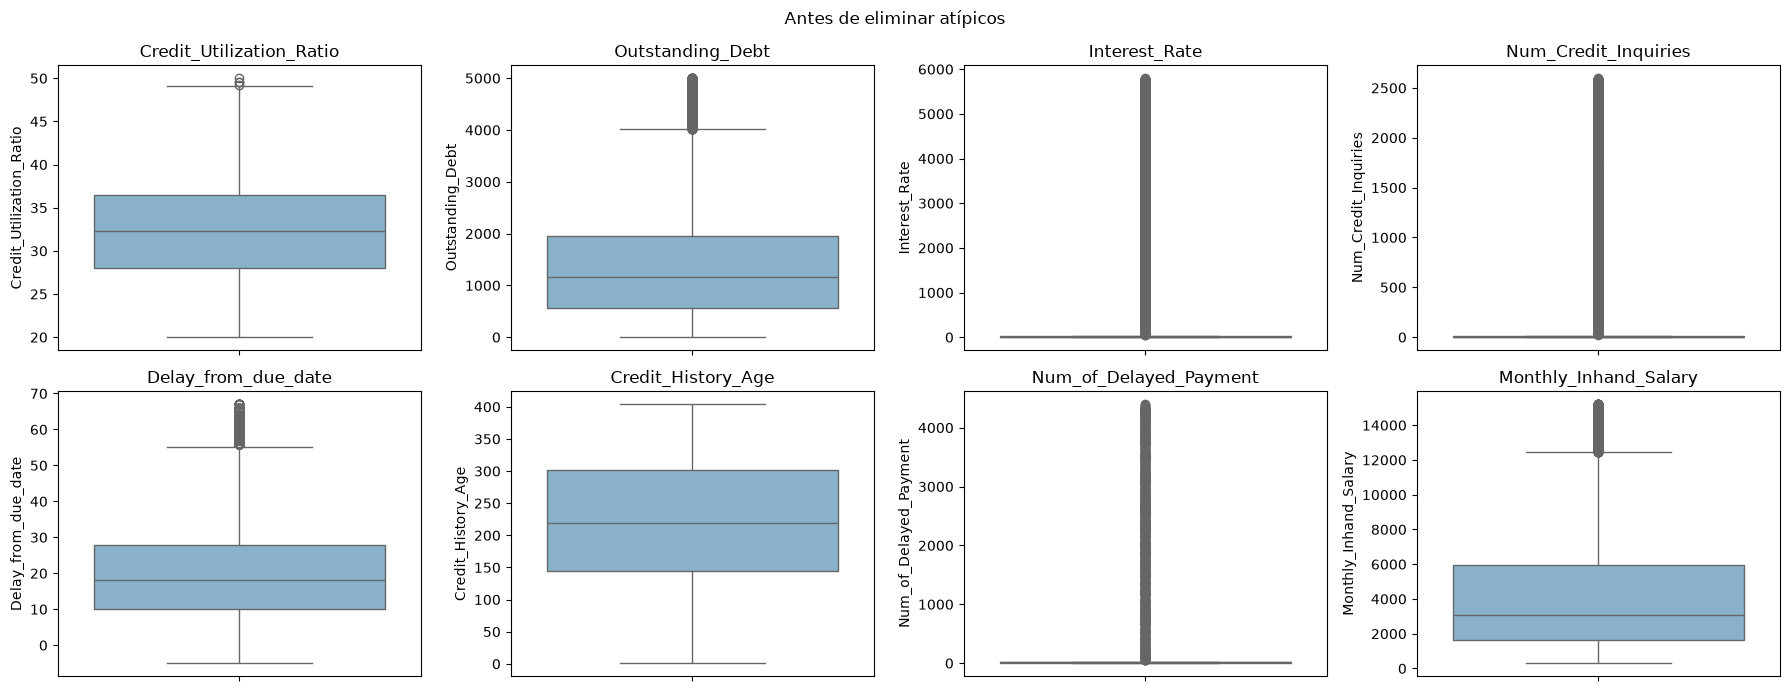

In [10]:
fig, ejes = plt.subplots(2, 4, figsize=(18, 7))
for eje, c in zip(ejes.ravel(), COLUMNAS_NUMERICAS):
    sns.boxplot(y=df[c], ax=eje, color='#7fb3d5')
    eje.set_title(c)
plt.suptitle('Antes de eliminar atípicos')
plt.tight_layout()
plt.show()

In [11]:
antes = df.shape[0]
df = pp.eliminar_atipicos_iqr(df, COLUMNAS_NUMERICAS)
print('Antes:', antes, '| Después:', df.shape[0], '| Eliminados:', antes - df.shape[0],
      f'({(antes - df.shape[0]) / antes:.1%})')

Antes: 100000 | Después: 84938 | Eliminados: 15062 (15.1%)


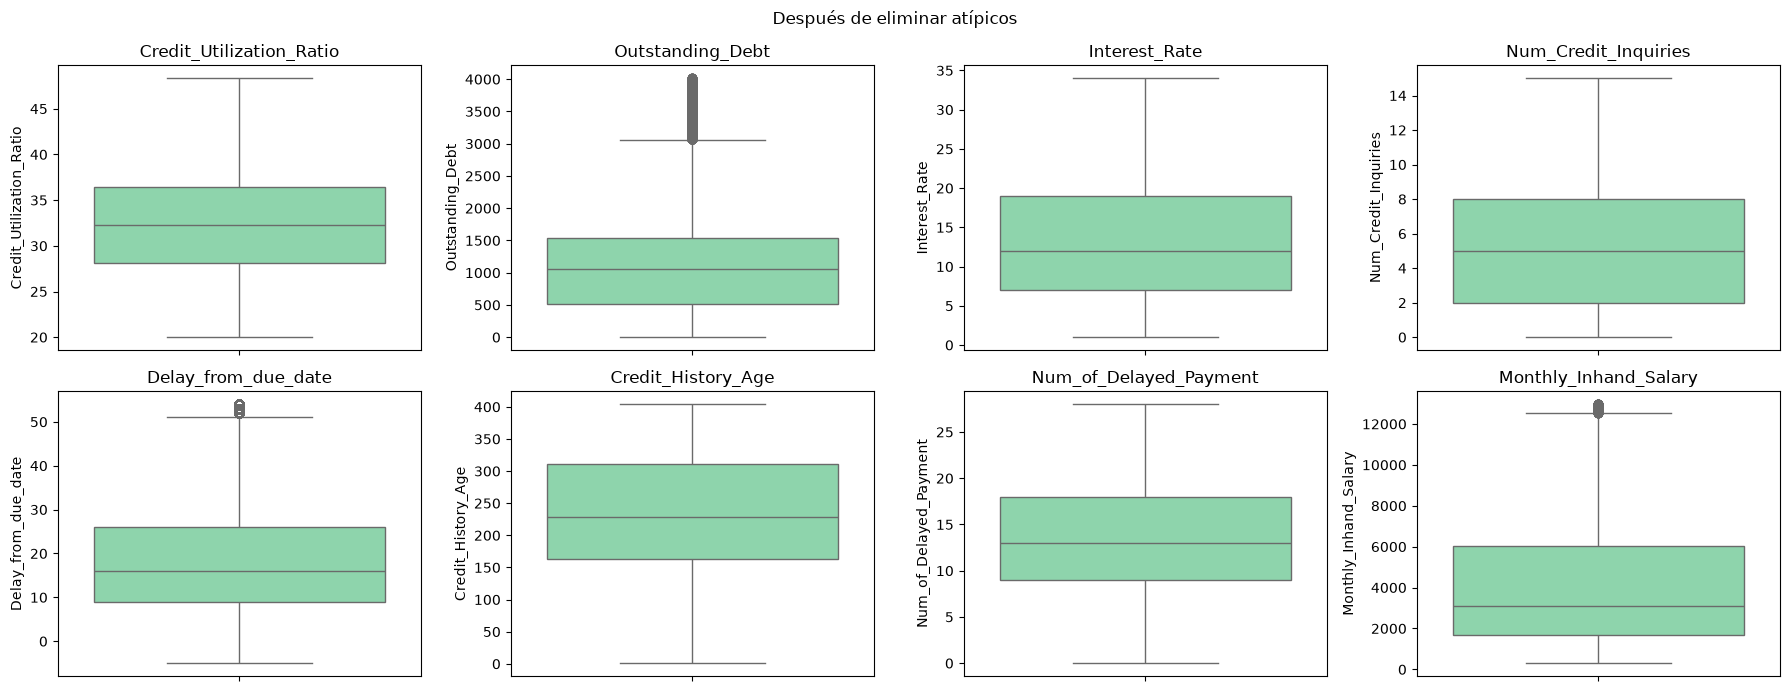

In [12]:
fig, ejes = plt.subplots(2, 4, figsize=(18, 7))
for eje, c in zip(ejes.ravel(), COLUMNAS_NUMERICAS):
    sns.boxplot(y=df[c], ax=eje, color='#82e0aa')
    eje.set_title(c)
plt.suptitle('Después de eliminar atípicos')
plt.tight_layout()
plt.show()

## 5. Codificación de variables categóricas

Las dos variables categóricas son **ordinales**, por lo que se usa label encoding con un diccionario:

- `Credit_Mix`: Bad = 0, Standard = 1, Good = 2
- `Payment_of_Min_Amount`: No = 0, Yes = 1
- `Credit_Score` (objetivo): Good = 0, Standard = 1, Poor = 2

In [13]:
antes_cod = df[COLUMNAS_CATEGORICAS + [COLUMNA_OBJETIVO]].head()
df = pp.codificar(df)
display(antes_cod)
display(df[COLUMNAS_CATEGORICAS + [COLUMNA_OBJETIVO]].head())

,Credit_Mix,Payment_of_Min_Amount,Credit_Score
0,Good,No,Good
1,Good,No,Good
2,Good,No,Good
3,Good,No,Good
4,Good,No,Good


,Credit_Mix,Payment_of_Min_Amount,Credit_Score
0,2,0,0
1,2,0,0
2,2,0,0
3,2,0,0
4,2,0,0


## 6. Análisis de las variables por nivel de riesgo

In [14]:
resumen = df.groupby(COLUMNA_OBJETIVO)[COLUMNAS_MODELO].median()
resumen.index = [ETIQUETAS_RIESGO[i] for i in resumen.index]
resumen.T

,Riesgo bajo,Riesgo medio,Riesgo alto
Credit_Utilization_Ratio,32.63,32.31,32.03
Outstanding_Debt,730.77,926.99,1773.45
Interest_Rate,7.00,12.00,20.00
Num_Credit_Inquiries,3.00,4.00,8.00
Delay_from_due_date,10.00,17.00,24.00
Credit_Mix,2.00,1.00,1.00
Payment_of_Min_Amount,0.00,1.00,1.00
Credit_History_Age,289.00,234.00,173.00
Num_of_Delayed_Payment,8.00,13.00,16.00
Monthly_Inhand_Salary,3671.50,3124.36,2697.51


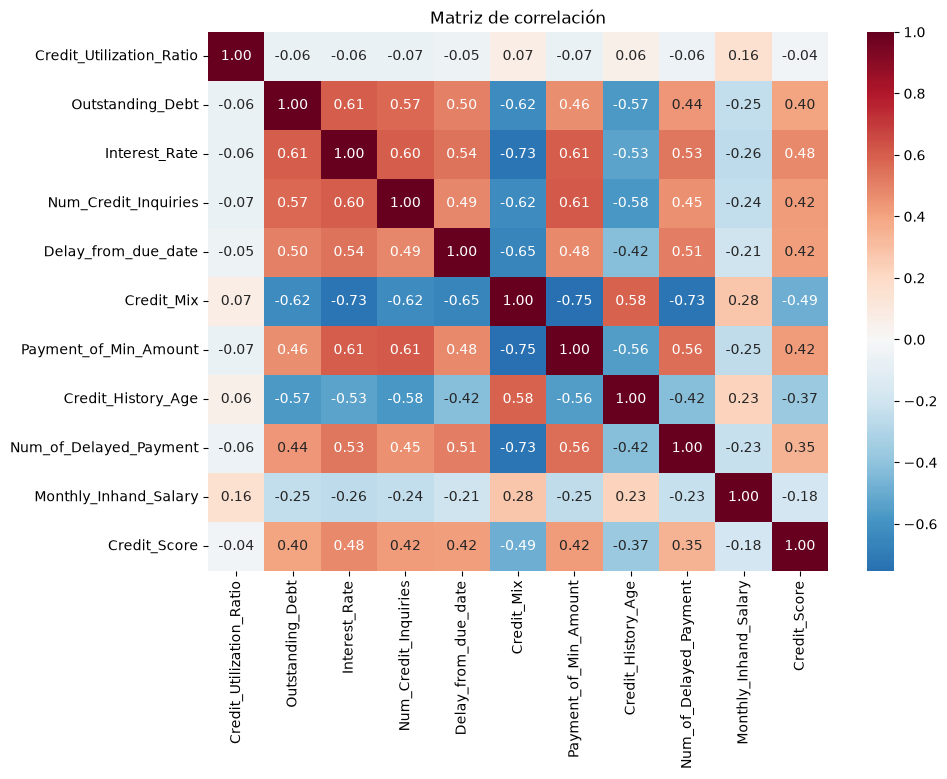

In [15]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[COLUMNAS_MODELO + [COLUMNA_OBJETIVO]].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Matriz de correlación')
plt.show()

## 7. Separación de X y y, división entrenamiento/prueba

La división 80/20 se hace **por cliente** (`GroupShuffleSplit`): los 8 meses de un mismo cliente quedan todos en entrenamiento o todos en prueba. Así el modelo se evalúa con clientes que no vio al entrenar.

In [16]:
X = df[COLUMNAS_MODELO]
y = df[COLUMNA_OBJETIVO]
grupos = df['Customer_ID']

X_train, X_test, y_train, y_test, grupos_train = ent.dividir(X, y, grupos)
print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Clientes en común entre train y test:', len(set(grupos_train) & set(grupos.loc[X_test.index])))

Entrenamiento: (67962, 10) | Prueba: (16976, 10)
Clientes en común entre train y test: 0


## 8. Escalado estándar

`StandardScaler` se ajusta solo con el conjunto de entrenamiento (`fit_transform`) y se aplica al de prueba (`transform`). En el modelo final el escalador forma parte de un `Pipeline` junto al clasificador, para que la API aplique exactamente la misma transformación.

In [17]:
from sklearn.preprocessing import StandardScaler
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)
pd.DataFrame(X_train_esc, columns=COLUMNAS_MODELO).describe().loc[['mean', 'std']].T

,mean,std
Credit_Utilization_Ratio,-0.00,1.00
Outstanding_Debt,-0.00,1.00
Interest_Rate,0.00,1.00
Num_Credit_Inquiries,0.00,1.00
Delay_from_due_date,0.00,1.00
Credit_Mix,0.00,1.00
Payment_of_Min_Amount,-0.00,1.00
Credit_History_Age,-0.00,1.00
Num_of_Delayed_Payment,-0.00,1.00
Monthly_Inhand_Salary,-0.00,1.00


## 9. Entrenamiento y comparación de modelos

Se comparan tres técnicas vistas en clase:

- **KNN**: se elige `k` con validación cruzada por cliente (GroupKFold, 3 particiones) usando F1 macro.
- **Árbol de decisión**: se elige `max_depth` con la misma validación cruzada.
- **SVC** (kernel rbf): entrenado con una muestra de 20 000 registros por costo computacional, calibrado para obtener probabilidades.

In [18]:
candidatos, busquedas = ent.entrenar_candidatos(X_train, y_train, grupos_train)
display(busquedas['knn'])
display(busquedas['arbol'])

,k,f1_macro_cv
0,5,0.61
1,15,0.64
2,31,0.65
3,51,0.66


,max_depth,f1_macro_cv
0,3,0.67
1,4,0.68
2,5,0.68
3,6,0.68
4,7,0.68
5,8,0.67
6,10,0.66


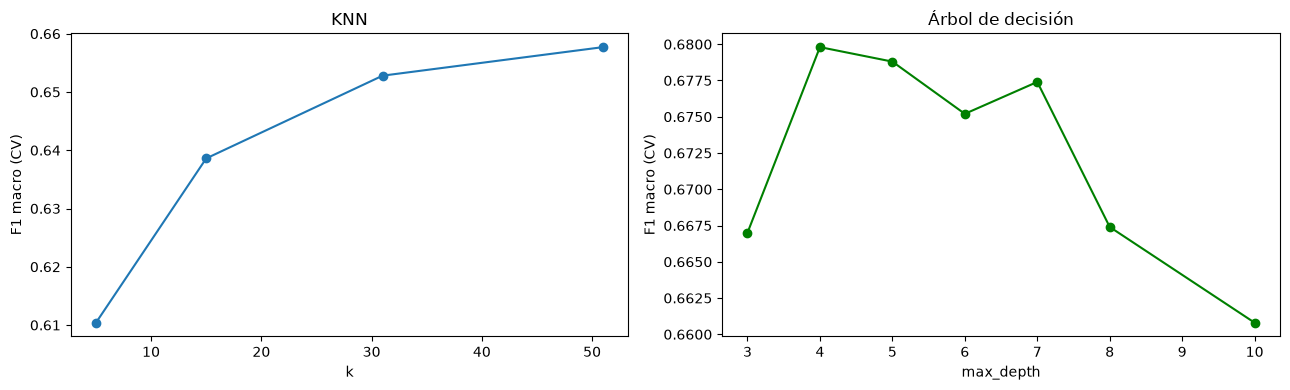

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
ejes[0].plot(busquedas['knn']['k'], busquedas['knn']['f1_macro_cv'], marker='o')
ejes[0].set_xlabel('k')
ejes[0].set_ylabel('F1 macro (CV)')
ejes[0].set_title('KNN')
ejes[1].plot(busquedas['arbol']['max_depth'], busquedas['arbol']['f1_macro_cv'], marker='o', color='green')
ejes[1].set_xlabel('max_depth')
ejes[1].set_ylabel('F1 macro (CV)')
ejes[1].set_title('Árbol de decisión')
plt.tight_layout()
plt.show()

## 10. Evaluación en el conjunto de prueba

In [20]:
tabla, resultados = ent.comparar(candidatos, X_test, y_test)
tabla

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
Árbol de decisión (max_depth=4),0.70,0.68,0.72,0.69,0.71
SVC rbf (muestra 20000),0.69,0.68,0.71,0.68,0.70
KNN (k=51),0.69,0.66,0.67,0.66,0.69


Se selecciona el modelo con mayor **F1 macro**. Las clases están desbalanceadas (riesgo medio ≈ 55 %), por lo que el accuracy por sí solo no es suficiente: F1 macro da el mismo peso a las tres clases.

In [21]:
mejor = tabla.index[0]
modelo_final = candidatos[mejor]
print('Modelo seleccionado:', mejor)

y_pred = modelo_final.predict(X_test)
nombres = [ETIQUETAS_RIESGO[i] for i in range(3)]
print(classification_report(y_test, y_pred, target_names=nombres))

Modelo seleccionado: Árbol de decisión (max_depth=4)
              precision    recall  f1-score   support

 Riesgo bajo       0.51      0.81      0.63      3224
Riesgo medio       0.84      0.67      0.75      9320
 Riesgo alto       0.69      0.69      0.69      4432

    accuracy                           0.70     16976
   macro avg       0.68      0.72      0.69     16976
weighted avg       0.74      0.70      0.71     16976



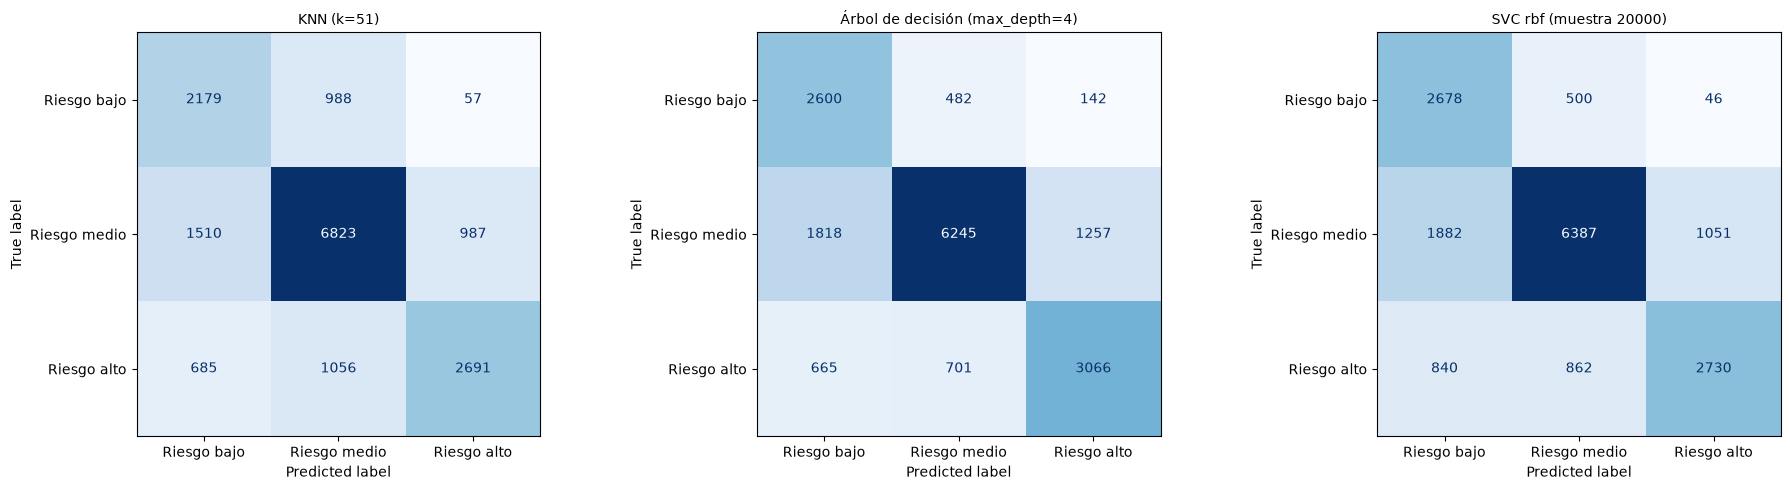

In [22]:
fig, ejes = plt.subplots(1, 3, figsize=(19, 5))
for eje, (nombre, modelo) in zip(ejes, candidatos.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, modelo.predict(X_test), display_labels=nombres,
                                            cmap='Blues', ax=eje, colorbar=False)
    eje.set_title(nombre, fontsize=10)
plt.tight_layout()
plt.show()

## 11. Interpretación del modelo seleccionado

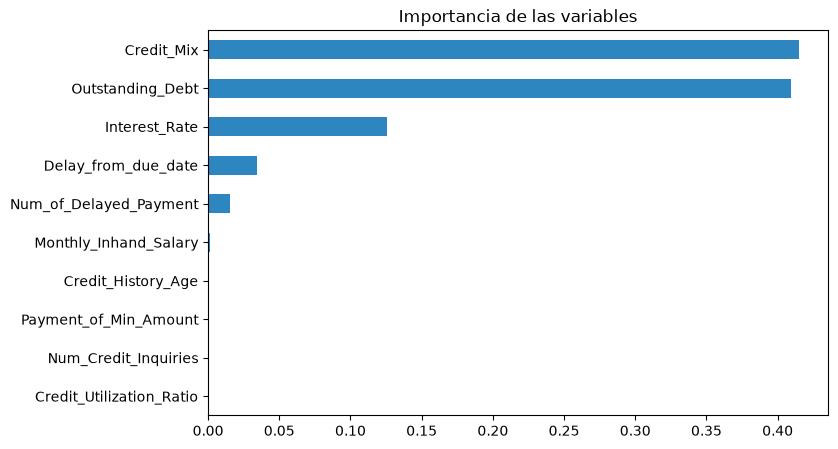

Profundidad: 4 | Nodos: 31


In [23]:
clasificador = modelo_final.named_steps['clasificador']
if hasattr(clasificador, 'feature_importances_'):
    importancias = pd.Series(clasificador.feature_importances_, index=COLUMNAS_MODELO).sort_values()
    importancias.plot.barh(figsize=(8, 5), color='#2e86c1', title='Importancia de las variables')
    plt.show()
    print('Profundidad:', clasificador.get_depth(), '| Nodos:', clasificador.tree_.node_count)

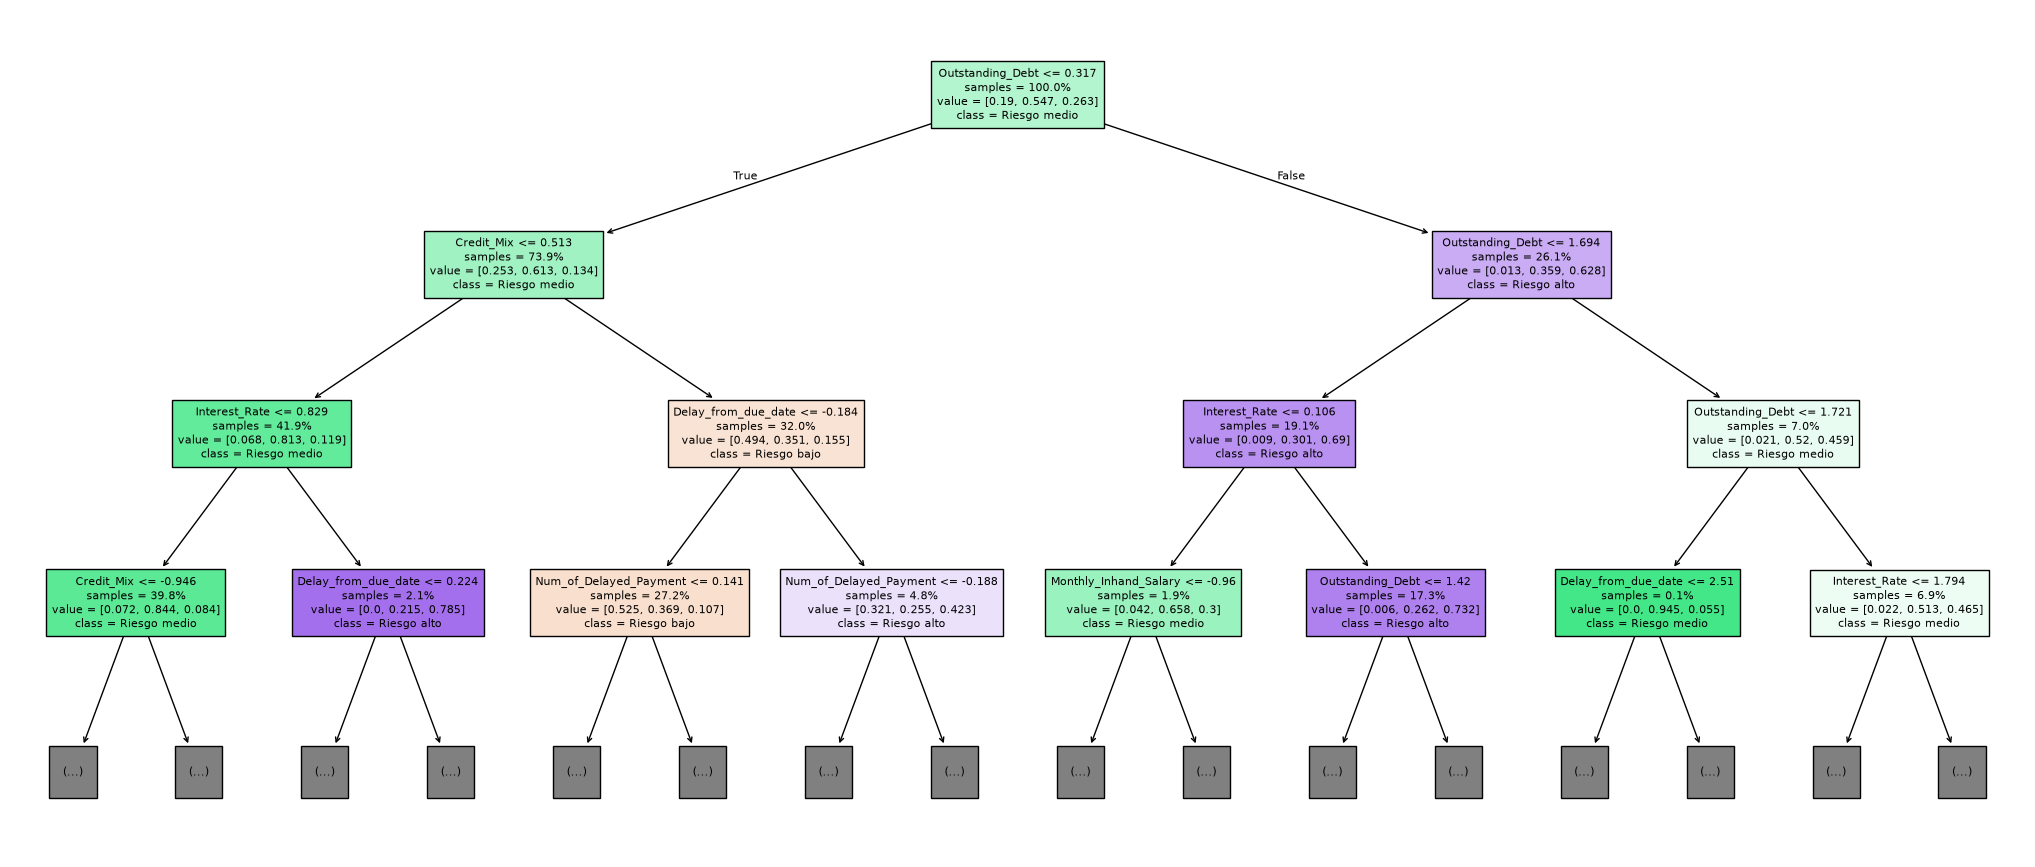

In [24]:
if hasattr(clasificador, 'tree_'):
    plt.figure(figsize=(26, 11))
    tree.plot_tree(clasificador, feature_names=COLUMNAS_MODELO, class_names=nombres,
                   filled=True, max_depth=3, fontsize=8, impurity=False, proportion=True)
    plt.show()

## 12. Guardado del modelo

Se guarda un paquete con `joblib` que contiene el `Pipeline` (escalador + clasificador), el orden de las columnas, los diccionarios de codificación, las medianas por nivel de riesgo (usadas por el agente para justificar) y los rangos de entrenamiento.

In [25]:
paquete = ent.guardar_artefactos(mejor, modelo_final, resultados[mejor], tabla, X, y)
print('Guardado en:', ent.RUTA_MODELO)
print('Métricas en:', ent.RUTA_METRICAS)

Guardado en: C:\Users\corre\OneDrive\Desktop\Proyecto IA\modelo\artefactos\modelo_riesgo.joblib
Métricas en: C:\Users\corre\OneDrive\Desktop\Proyecto IA\modelo\artefactos\metricas.json


In [26]:
import joblib
cargado = joblib.load(ent.RUTA_MODELO)
ejemplo = {'Credit_Utilization_Ratio': 25.63, 'Outstanding_Debt': 1886.54, 'Interest_Rate': 17,
           'Num_Credit_Inquiries': 12, 'Delay_from_due_date': 13, 'Credit_Mix': 'Standard',
           'Payment_of_Min_Amount': 'Yes', 'Credit_History_Age': 225, 'Num_of_Delayed_Payment': 16,
           'Monthly_Inhand_Salary': 971.16}
X_ej = pp.solicitud_a_dataframe(ejemplo)
proba = cargado['modelo'].predict_proba(X_ej)[0]
clase = int(proba.argmax())
print('Predicción:', clase, '→', ETIQUETAS_RIESGO[clase], f'| score = {proba.max():.2f}')

Predicción: 2 → Riesgo alto | score = 0.76
